# AT&T Spam Detector

Jedha, Deep Learning project. Goal: automatically flag SMS as **spam** or **ham** based only on their content.

Plan:
1. Data loading, cleaning, deduplication and EDA
2. Preprocessing (stratified train/validation/test split, Keras `TextVectorization`)
3. Reference baseline (TF-IDF + logistic regression, not deep learning)
4. Deep learning models
   - Model 1: Embedding + Global Average Pooling ("start simple")
   - Model 2: Embedding + Bidirectional LSTM
   - Model 3: **Transfer learning**: frozen pre-trained word vectors (spaCy `en_core_web_md`, trained on a large web corpus) + Bidirectional GRU
   - Model 4 (optional, off by default): fine-tuning DistilBERT, never executed here, so it has no score
5. Model choice on the validation set, then one final evaluation on the test set

The hyperparameters of the models are usual settings: they were not optimised.

### Setup

This cell installs the missing libraries in the environment of this kernel, so that the notebook can run on a new machine. If it installs something, restart the kernel once and run all cells again. No output is saved here.

In [1]:
import sys, subprocess, importlib
REQUIRED = {'tensorflow': 'tensorflow', 'spacy': 'spacy', 'sklearn': 'scikit-learn',
            'pandas': 'pandas', 'matplotlib': 'matplotlib', 'numpy': 'numpy'}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Installing:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
if importlib.util.find_spec('en_core_web_md') is None:
    print('Downloading spaCy pre-trained vectors (en_core_web_md, ~40 MB)...')
    subprocess.check_call([sys.executable, '-m', 'spacy', 'download', 'en_core_web_md'])
importlib.invalidate_caches()
print('Environment ready. Python:', sys.executable)

This cell imports the libraries and fixes the random seed to 42, so that a new run gives the same results. The output shows TensorFlow 2.21.0.

In [2]:
import os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report)
SEED = 42
keras.utils.set_random_seed(SEED)
pd.set_option('display.max_colwidth', 120)
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## 1. Data

This cell loads `spam.csv` in latin-1, the encoding of this file. It tries the local file first, then the address given in the brief. The output shows 5,572 rows and 5 columns: `v1` (the label), `v2` (the text) and 3 `Unnamed` columns.

In [3]:
DATA_URL = 'https://full-stack-bigdata-datasets.s3.eu-west-3.amazonaws.com/Deep+Learning/project/spam.csv'
for src in ['spam.csv', DATA_URL]:
    try:
        raw = pd.read_csv(src, encoding='latin-1'); print('Loaded from', src); break
    except Exception as e:
        print('Could not load', src, '->', type(e).__name__)
print(raw.shape)
raw.head()

Loaded from spam.csv
(5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives around here though",NaN,NaN,NaN


The file has 3 almost empty extra columns (`Unnamed: 2..4`): they contain the end of a few messages that were split on commas. Deleting them would cut the end of these messages, so this cell merges them back into the text and creates the target `y`, with 1 for spam. The output shows 50, 12 and 6 non-empty values in these columns.

In [4]:
extra = [c for c in raw.columns if c.startswith('Unnamed')]
print('Non-null values in extra columns:', raw[extra].notna().sum().to_dict())
df = pd.DataFrame({
    'label': raw['v1'],
    'text': raw[['v2'] + extra].fillna('').astype(str).agg(' '.join, axis=1).str.strip(),
})
df['y'] = (df['label'] == 'spam').astype(int)
df.head()

Non-null values in extra columns: {'Unnamed: 2': 50, 'Unnamed: 3': 12, 'Unnamed: 4': 6}


,label,text,y
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives around here though",0


This cell cleans the text: lowercase, numbers replaced by a `num` token, URLs by `url`, currency symbols kept as words. It then removes the duplicates on the cleaned text. The output shows 414 duplicates in the raw text and 476 after cleaning, because messages that differ only by a number become identical. This leaves 5,096 messages: 88.3% ham and 11.7% spam.

In [5]:
def clean(text):
    t = text.lower()
    t = re.sub(r'http\S+|www\.\S+', ' url ', t)
    t = t.replace('£', ' pound ').replace('$', ' dollar ').replace('&amp;', ' and ').replace('&lt;', ' ').replace('&gt;', ' ')
    t = re.sub(r'\d+', ' num ', t)
    t = re.sub(r"[^a-z' ]", ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

df['clean'] = df['text'].apply(clean)
print('Duplicates in the raw text:', df.duplicated('text').sum())
print('Duplicates after cleaning:', df.duplicated('clean').sum())
df = df.drop_duplicates('clean').reset_index(drop=True)
print('After deduplication:', df.shape)
df['label'].value_counts(normalize=True).round(3)

Duplicates in the raw text: 414
Duplicates after cleaning: 476
After deduplication: (5096, 4)


label
ham     0.883
spam    0.117
Name: proportion, dtype: float64

Duplicates are removed after cleaning and **before** splitting, otherwise identical messages could land in both train and test sets and inflate the scores. The dataset is imbalanced (about 12% spam): accuracy alone is misleading, because predicting always "ham" gives about 88%. So we track **precision, recall, F1 and ROC AUC** on the spam class.

### EDA

This cell compares the length of the messages and their number of digits, because these are simple signals of spam. The output shows a median of 149 characters and 16 digits for spam, against 53 characters and 0 digits for ham.

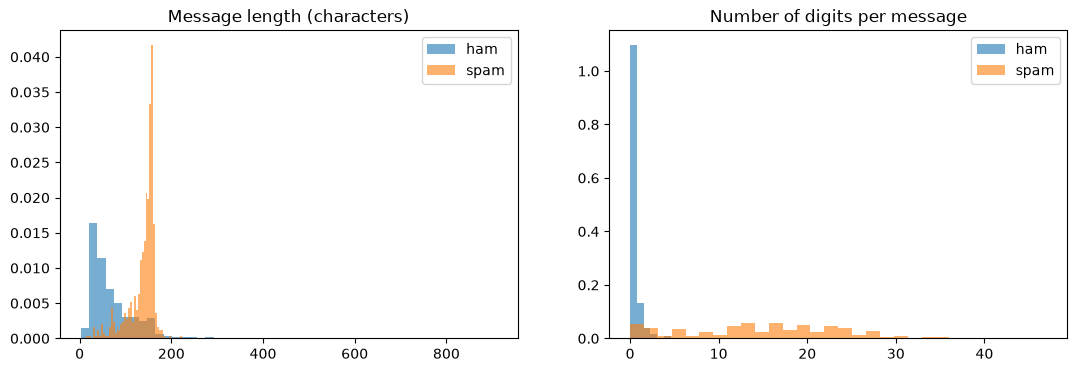

,n_chars,n_digits
label,,
ham,53.0,0.0
spam,149.0,16.0


In [6]:
df['n_chars'] = df['text'].str.len()
df['n_digits'] = df['text'].str.count(r'\d')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for lab, g in df.groupby('label'):
    ax[0].hist(g['n_chars'], bins=50, alpha=0.6, label=lab, density=True)
    ax[1].hist(g['n_digits'], bins=30, alpha=0.6, label=lab, density=True)
ax[0].set_title('Message length (characters)'); ax[1].set_title('Number of digits per message')
for a in ax: a.legend()
plt.show()
df.groupby('label')[['n_chars', 'n_digits']].median()

This cell counts the most frequent words in each class, to see the vocabulary of spam. The output shows `call` (278), `free` (183) and `txt` (133) for spam, while the top words for ham are common words such as `you` (1,878) and `the` (1,066). Stop words are kept here, so they also appear in spam.

In [7]:
from collections import Counter
def top_tokens(texts, n=15):
    toks = re.findall(r"[a-z£$]+", ' '.join(texts).lower())
    return Counter(t for t in toks if len(t) > 2).most_common(n)
print('SPAM:', top_tokens(df.loc[df.y == 1, 'text']))
print('HAM :', top_tokens(df.loc[df.y == 0, 'text']))

SPAM: [('call', 278), ('you', 238), ('your', 221), ('free', 183), ('the', 168), ('for', 166), ('now', 159), ('txt', 133), ('stop', 115), ('from', 114), ('text', 106), ('have', 101), ('mobile', 101), ('and', 100), ('reply', 91)]
HAM : [('you', 1878), ('the', 1066), ('and', 824), ('that', 547), ('for', 480), ('have', 426), ('can', 421), ('but', 420), ('are', 398), ('not', 393), ('your', 381), ('will', 318), ('get', 301), ('how', 299), ('just', 282)]


Spams are longer, contain many digits (phone numbers, short codes, prices) and a typical vocabulary (*call, free, txt, stop, mobile, reply*).

## 2. Preprocessing

Stop words are **kept**: in short SMS they carry signal, and deep models learn their weight.

This cell splits the data: 70% train, 15% validation, 15% test. Stratifying keeps the same share of spam in each part. In this version of the notebook, the test set is only used at the end, on the selected model. The output shows 3,567 messages for training, 764 for validation and 765 for test, with 0 test messages also in training. It also shows 5 examples of messages before and after cleaning.

In [8]:
X_train, X_tmp, y_train, y_tmp = train_test_split(df['clean'].values, df['y'].values, test_size=0.30, stratify=df['y'], random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(f'train {len(X_train)} | val {len(X_val)} | test {len(X_test)} | spam rate train {y_train.mean():.3f} test {y_test.mean():.3f}')
print('Test messages also in train:', len(set(X_train) & set(X_test)))
df[['text', 'clean']].sample(5, random_state=SEED)

train 3567 | val 764 | test 765 | spam rate train 0.117 test 0.118
Test messages also in train: 0


,text,clean
996,May i call You later Pls,may i call you later pls
3483,"Nah, Wednesday. When should I bring the mini cheetos bag over?",nah wednesday when should i bring the mini cheetos bag over
848,"Well am officially in a philosophical hole, so if u wanna call am at home ready to be saved!",well am officially in a philosophical hole so if u wanna call am at home ready to be saved
3409,Wait.i will come out.. &lt;#&gt; min:),wait i will come out min
79,Its not the same here. Still looking for a job. How much do Ta's earn there.,its not the same here still looking for a job how much do ta's earn there


This cell measures what the deduplication on the cleaned text prevents. It repeats the same split on the data deduplicated on the raw text only, and counts the test messages that are identical to a training message after cleaning. It also gives the number of spams in the current data. The output shows 17 such test messages, of which 11 are spams, against 0 now.


In [9]:
raw_dedup = pd.DataFrame({'text': raw[['v2'] + extra].fillna('').astype(str).agg(' '.join, axis=1).str.strip(), 'label': raw['v1']})
raw_dedup = raw_dedup.drop_duplicates('text').reset_index(drop=True)
raw_dedup['clean'] = raw_dedup['text'].apply(clean)
raw_dedup['y'] = (raw_dedup['label'] == 'spam').astype(int)
old_train, old_tmp, old_y_train, old_y_tmp = train_test_split(raw_dedup['clean'].values, raw_dedup['y'].values, test_size=0.30, stratify=raw_dedup['y'], random_state=SEED)
_, old_test, _, old_y_test = train_test_split(old_tmp, old_y_tmp, test_size=0.50, stratify=old_y_tmp, random_state=SEED)
seen = np.isin(old_test, old_train)
print('Deduplication on the raw text: test messages also in train:', seen.sum(), '| of which spams:', old_y_test[seen].sum())
print('Current data: messages', len(df), '| spams', df['y'].sum(), '| spams in validation', y_val.sum(), '| spams in test', y_test.sum())


Deduplication on the raw text: test messages also in train: 17 | of which spams: 11
Current data: messages 5096 | spams 597 | spams in validation 89 | spams in test 90


This cell turns each message into a sequence of word numbers, because a network works on numbers. The vocabulary is learned on the training set only, so that the test set stays unknown. Sequences have 60 positions, a usual setting: the output shows that 99% of training messages have 48 words or fewer, with a maximum of 162. Longer messages are cut. The vocabulary has 6,376 entries.

In [10]:
lengths = pd.Series(X_train).str.split().str.len()
print(lengths.describe(percentiles=[.5, .9, .95, .99]).round(1))
MAX_TOKENS = 10_000
SEQ_LEN = 60   # covers > 99% of messages
vectorizer = layers.TextVectorization(max_tokens=MAX_TOKENS, output_sequence_length=SEQ_LEN, standardize=None)
vectorizer.adapt(X_train)
vocab = vectorizer.get_vocabulary()
print('Vocabulary size:', len(vocab))
to_seq = lambda x: vectorizer(tf.constant(x)).numpy()
S_train, S_val, S_test = to_seq(X_train), to_seq(X_val), to_seq(X_test)
S_train.shape

count    3567.0
mean       15.7
std        11.2
min         0.0
50%        12.0
90%        31.0
95%        34.0
99%        48.0
max       162.0
dtype: float64


Vocabulary size: 6376


(3567, 60)

**Class imbalance:** spam is rare, so a model could ignore it and still look good. Class weights give spam errors more weight during training (`n_samples / (2 * n_class)`). The output shows a weight of 0.57 for ham and 4.27 for spam.

In [11]:
neg, pos = np.bincount(y_train)
class_weight = {0: len(y_train) / (2 * neg), 1: len(y_train) / (2 * pos)}
class_weight

{0: np.float64(0.5663702762781836), 1: np.float64(4.266746411483253)}

## 3. Reference baseline (not deep learning): TF-IDF + logistic regression

This cell trains a simple classical model, to judge whether the deep models bring something. TF-IDF gives each word and pair of words a weight, higher when it is frequent in a message and rare elsewhere. A logistic regression then learns a weight per term. `ngram_range`, `min_df` and `C` are usual settings, not optimised. This model is a reference only: it cannot be selected, because the brief asks for a deep learning model. There is no output here: the scores are in section 5.

In [12]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
lr = LogisticRegression(max_iter=2000, class_weight='balanced', C=10)
lr.fit(tfidf.fit_transform(X_train), y_train)
p_val_lr = lr.predict_proba(tfidf.transform(X_val))[:, 1]

## 4. Deep learning models

This cell defines the common training setup, so that the models are compared under the same rules: Adam, binary cross-entropy and class weights. Early stopping ends training when the validation loss stops improving, and restores the best weights, which limits overfitting. The learning rate, batch size and patience are usual settings, not optimised. Patience is the one difference: 5 for M1, 3 for M2 and M3. There is no output: the functions are only defined here.

In [13]:
METRICS = [keras.metrics.BinaryAccuracy(name='accuracy'), keras.metrics.Precision(name='precision'),
           keras.metrics.Recall(name='recall'), keras.metrics.AUC(name='auc')]

def train(model, epochs=40, lr=1e-3, batch_size=32, x_tr=None, x_va=None, patience=3):
    x_tr = S_train if x_tr is None else x_tr
    x_va = S_val if x_va is None else x_va
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='binary_crossentropy', metrics=METRICS)
    es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True)
    hist = model.fit(x_tr, y_train, validation_data=(x_va, y_val), epochs=epochs, batch_size=batch_size,
                     class_weight=class_weight, callbacks=[es], verbose=0)
    print(f'{model.name}: stopped after {len(hist.history["loss"])} epochs, best val_loss={min(hist.history["val_loss"]):.4f}')
    return hist

def plot_history(hist, title):
    h = pd.DataFrame(hist.history)
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
    for a, m in zip(ax, ['loss', 'recall', 'precision']):
        a.plot(h[m], label='train'); a.plot(h['val_' + m], label='validation'); a.set_title(f'{title}: {m}'); a.set_xlabel('epoch'); a.legend()
    plt.tight_layout(); plt.show()

### Model 1: Embedding + Global Average Pooling (start simple)

The brief says to start simple. Each word gets a learned vector of 32 values, the message is the average of its word vectors, padding positions included (no mask, see the code comment), and a small dense layer decides. This model ignores word order. The layer sizes are usual settings, not optimised. The output shows 320,545 parameters and training stopped after 30 epochs, with a best validation loss of 0.0460.

Model: "m1_embedding_avgpool"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 60, 32)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 320,545 (1.22 MB)

 Trainable params: 320,545 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

m1_embedding_avgpool: stopped after 30 epochs, best val_loss=0.0460


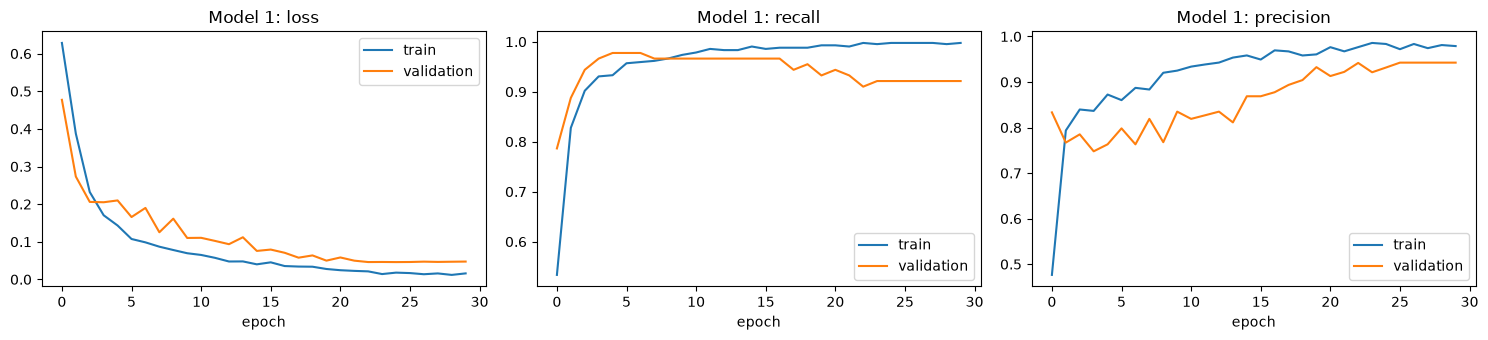

In [14]:
keras.utils.set_random_seed(SEED)
m1 = keras.Sequential([
    keras.Input(shape=(SEQ_LEN,), dtype='int64'),
    layers.Embedding(MAX_TOKENS, 32),  # no mask_zero here: with Keras 3, masking + GlobalAveragePooling1D blocks learning (constant output)
    layers.GlobalAveragePooling1D(),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid'),
], name='m1_embedding_avgpool')
m1.summary()
h1 = train(m1, patience=5)
plot_history(h1, 'Model 1')

### Model 2: Embedding + Bidirectional LSTM

The LSTM reads the message in both directions and keeps word order, which the first model ignores. The layer sizes are usual settings, not optimised. The output shows 664,897 parameters and training stopped after 8 epochs, with a best validation loss of 0.0833.

Model: "m2_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 60, 64)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 664,897 (2.54 MB)

 Trainable params: 664,897 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

m2_bilstm: stopped after 8 epochs, best val_loss=0.0833


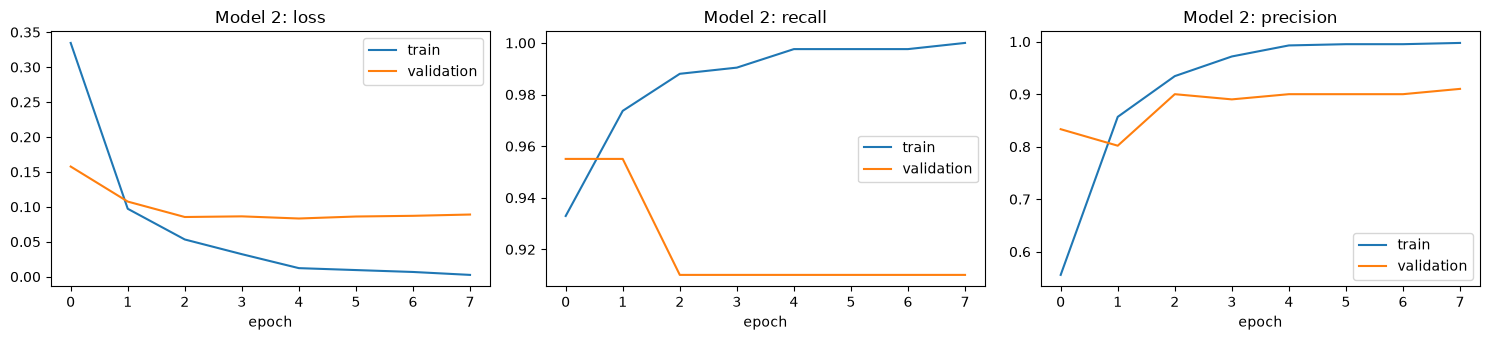

In [15]:
keras.utils.set_random_seed(SEED)
m2 = keras.Sequential([
    keras.Input(shape=(SEQ_LEN,), dtype='int64'),
    layers.Embedding(MAX_TOKENS, 64, mask_zero=True),
    layers.Bidirectional(layers.LSTM(32)),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid'),
], name='m2_bilstm')
m2.summary()
h2 = train(m2)
plot_history(h2, 'Model 2')

### Model 3: Transfer learning with pre-trained word vectors

We have only 3,567 training messages, and the brief suggests transfer learning. Instead of learning word vectors from scratch, this cell loads the 300-value vectors of spaCy `en_core_web_md`, trained on a large web corpus. The output shows vectors for 5,512 of the 6,374 words of the vocabulary (86%).

In [16]:
import spacy
nlp_vec = spacy.load('en_core_web_md', exclude=['tagger', 'parser', 'ner', 'lemmatizer', 'attribute_ruler', 'senter'])
EMB_DIM = nlp_vec.vocab.vectors_length
emb_matrix = np.zeros((len(vocab), EMB_DIM), dtype='float32')
hits = 0
for i, w in enumerate(vocab):
    if i < 2: continue  # padding and OOV tokens
    if nlp_vec.vocab.has_vector(w):
        emb_matrix[i] = nlp_vec.vocab.get_vector(w); hits += 1
print(f'Pre-trained vectors found for {hits}/{len(vocab) - 2} words ({hits / (len(vocab) - 2):.0%})')

Pre-trained vectors found for 5512/6374 words (86%)


This cell builds the model on these vectors. The embedding layer is **frozen**, and only the GRU and the classifier are trained. The layer sizes are usual settings, not optimised. The output shows 1,976,993 parameters, of which only 64,193 are trained. Training stopped after 13 epochs, with a best validation loss of 0.0386, the lowest of the three models.

Model: "m3_pretrained_vectors_bigru"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 60, 300)        │     1,912,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 64)             │        64,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,976,993 (7.54 MB)

 Trainable params: 64,193 (250.75 KB)

 Non-trainable params: 1,912,800 (7.30 MB)

m3_pretrained_vectors_bigru: stopped after 13 epochs, best val_loss=0.0386


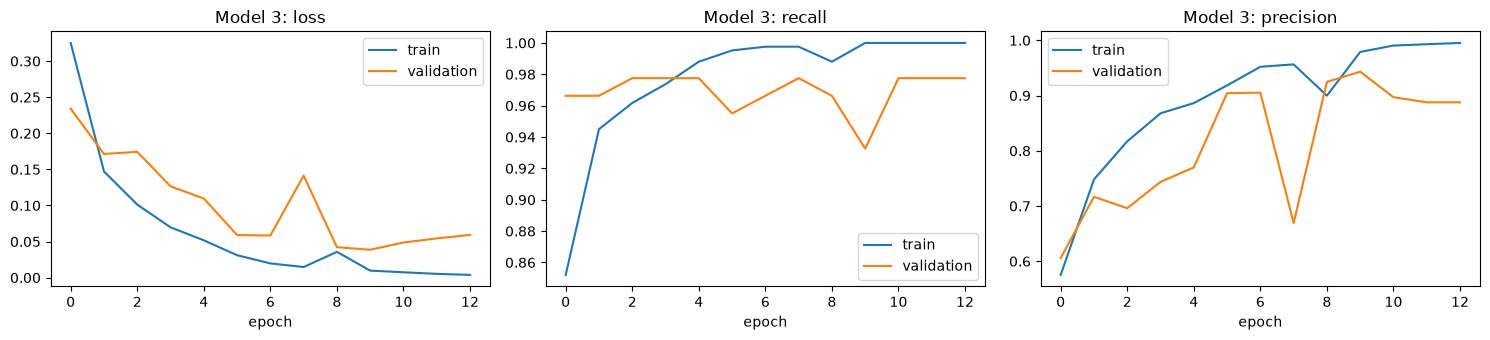

In [17]:
keras.utils.set_random_seed(SEED)
m3 = keras.Sequential([
    keras.Input(shape=(SEQ_LEN,), dtype='int64'),
    layers.Embedding(len(vocab), EMB_DIM, embeddings_initializer=keras.initializers.Constant(emb_matrix),
                     trainable=False, mask_zero=True),
    layers.Bidirectional(layers.GRU(32)),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid'),
], name='m3_pretrained_vectors_bigru')
m3.summary()
h3 = train(m3)
plot_history(h3, 'Model 3')

### Model 4 (optional): fine-tuning DistilBERT

A pre-trained transformer, fine-tuned on our SMS. Set `RUN_DISTILBERT = True` to run it. It downloads about 260 MB from Hugging Face and installs `torch` and `transformers`; on CPU expect roughly 10 to 20 minutes for 2 epochs, much less on GPU.

The code is present, but it was not executed: the output shows "DistilBERT skipped". **This model has no score.**

In [18]:
RUN_DISTILBERT = False
p_val_bert = p_test_bert = None
if RUN_DISTILBERT:
    for mod, pkg in [('torch', 'torch'), ('transformers', 'transformers')]:
        if importlib.util.find_spec(mod) is None:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
    import torch
    from torch.utils.data import DataLoader, TensorDataset
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    torch.manual_seed(SEED)
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    name = 'distilbert-base-uncased'
    tok = AutoTokenizer.from_pretrained(name)
    bert = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2).to(device)
    # raw text (not the cleaned version): the BERT tokenizer handles casing, digits and punctuation itself
    raw_text = df.set_index('clean')['text']
    def encode(x, y=None):
        enc = tok([raw_text.loc[t] if isinstance(raw_text.loc[t], str) else raw_text.loc[t].iloc[0] for t in x],
                  truncation=True, padding='max_length', max_length=64, return_tensors='pt')
        tensors = [enc['input_ids'], enc['attention_mask']] + ([torch.tensor(y)] if y is not None else [])
        return TensorDataset(*tensors)
    train_dl = DataLoader(encode(X_train, y_train), batch_size=16, shuffle=True)
    weights = torch.tensor([class_weight[0], class_weight[1]], dtype=torch.float).to(device)
    opt = torch.optim.AdamW(bert.parameters(), lr=3e-5)
    loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
    for epoch in range(2):
        bert.train(); total = 0
        for ids, mask, yb in train_dl:
            ids, mask, yb = ids.to(device), mask.to(device), yb.to(device)
            opt.zero_grad(); loss = loss_fn(bert(input_ids=ids, attention_mask=mask).logits, yb)
            loss.backward(); opt.step(); total += loss.item()
        print(f'epoch {epoch + 1}: train loss {total / len(train_dl):.4f}')
    @torch.no_grad()
    def bert_proba(x):
        bert.eval(); out = []
        for ids, mask in DataLoader(encode(x), batch_size=64):
            out.append(torch.softmax(bert(input_ids=ids.to(device), attention_mask=mask.to(device)).logits, -1)[:, 1].cpu().numpy())
        return np.concatenate(out)
    p_val_bert, p_test_bert = bert_proba(X_val), bert_proba(X_test)
else:
    print('DistilBERT skipped (RUN_DISTILBERT = False)')

DistilBERT skipped (RUN_DISTILBERT = False)


## 5. Evaluation

### Comparison on the validation set

The default threshold is 0.5. Because spam is rare, this cell picks, for each model, the threshold that maximises F1 on the **validation** set, then gives its scores on that same set. F1 combines precision and recall on the spam class. These scores are slightly optimistic, because the threshold is tuned on the same data, but this is the same for all models. The test set is not used here.

The output shows, for 89 spams: pre-trained vectors with BiGRU 95.40%, simple model 94.12%, TF-IDF baseline 92.86% and BiLSTM 92.49%. The thresholds go from 0.66 to 0.91.

In [19]:
def best_threshold(y, p):
    grid = np.linspace(0.05, 0.95, 91)
    return grid[np.argmax([f1_score(y, p >= t) for t in grid])]

def scores(y, p, t):
    pred = (p >= t).astype(int)
    return {'accuracy': accuracy_score(y, pred), 'precision': precision_score(y, pred), 'recall': recall_score(y, pred),
            'f1': f1_score(y, pred), 'roc_auc': roc_auc_score(y, p), 'threshold': t}

probas_val = {
    'Baseline TF-IDF + LogReg (not DL)': p_val_lr,
    'M1 Embedding + AvgPool': m1.predict(S_val, verbose=0).ravel(),
    'M2 Embedding + BiLSTM': m2.predict(S_val, verbose=0).ravel(),
    'M3 Pre-trained vectors + BiGRU': m3.predict(S_val, verbose=0).ravel(),
}
if p_val_bert is not None:
    probas_val['M4 DistilBERT fine-tuned'] = p_val_bert

rows = []
for name, pv in probas_val.items():
    rows.append({'model': name, **scores(y_val, pv, best_threshold(y_val, pv))})
results = pd.DataFrame(rows).set_index('model').round(4).sort_values('f1', ascending=False)
results

,accuracy,precision,recall,f1,roc_auc,threshold
model,,,,,,
M3 Pre-trained vectors + BiGRU,0.9895,0.9765,0.9326,0.9540,0.9956,0.66
M1 Embedding + AvgPool,0.9869,0.9877,0.8989,0.9412,0.9956,0.88
Baseline TF-IDF + LogReg (not DL),0.9843,0.9873,0.8764,0.9286,0.9946,0.83
M2 Embedding + BiLSTM,0.9830,0.9524,0.8989,0.9249,0.9863,0.91


This chart shows precision, recall, F1 and ROC AUC on the validation set, with an axis starting at 0.7 to make the gaps visible. Read it with care: this axis makes small gaps look large, and one spam is worth more than 1 point of recall.

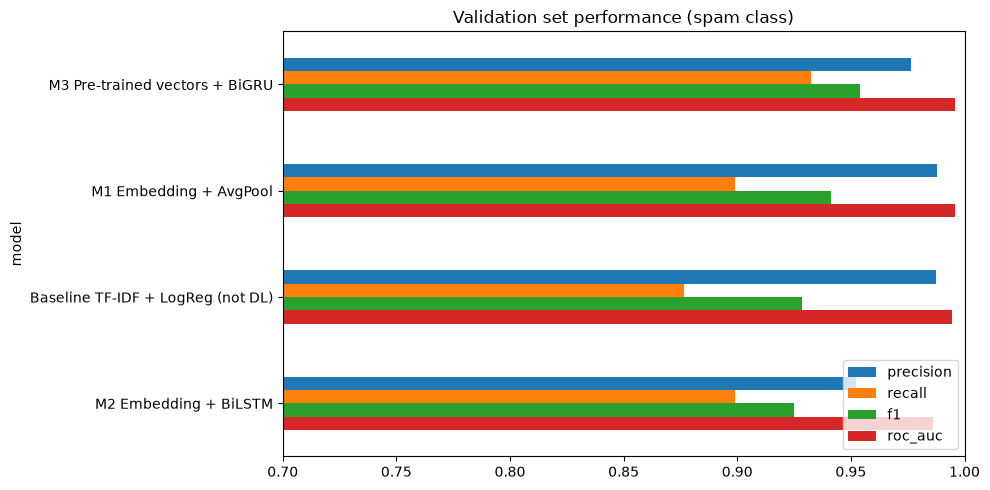

In [20]:
ax = results[['precision', 'recall', 'f1', 'roc_auc']].plot.barh(figsize=(10, 5), xlim=(0.7, 1.0))
ax.set_title('Validation set performance (spam class)'); ax.invert_yaxis(); plt.tight_layout(); plt.show()

### Selected model: final evaluation on the test set

This cell selects the deep learning model with the best validation F1. The TF-IDF baseline cannot be selected. It then evaluates this model only on the test set. The output shows the pre-trained vectors with BiGRU, with a threshold of 0.66. On 765 messages, it finds 79 of the 90 spams (recall 87.78%), and it wrongly flags 5 of the 675 legitimate messages (precision 94.05%).

Model selected on validation F1: M3 Pre-trained vectors + BiGRU (threshold 0.66)

              precision    recall  f1-score   support

         ham     0.9838    0.9926    0.9882       675
        spam     0.9405    0.8778    0.9080        90

    accuracy                         0.9791       765
   macro avg     0.9622    0.9352    0.9481       765
weighted avg     0.9787    0.9791    0.9788       765



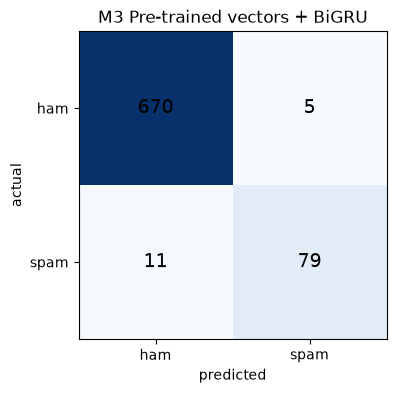

In [21]:
dl_results = results[~results.index.str.contains('not DL')]
best_name = dl_results['f1'].idxmax()
t = results.loc[best_name, 'threshold']
test_predict = {
    'M1 Embedding + AvgPool': lambda: m1.predict(S_test, verbose=0).ravel(),
    'M2 Embedding + BiLSTM': lambda: m2.predict(S_test, verbose=0).ravel(),
    'M3 Pre-trained vectors + BiGRU': lambda: m3.predict(S_test, verbose=0).ravel(),
    'M4 DistilBERT fine-tuned': lambda: p_test_bert,
}
pt = test_predict[best_name]()
pred = (pt >= t).astype(int)
test_scores = scores(y_test, pt, t)
print('Model selected on validation F1:', best_name, f'(threshold {t:.2f})\n')
print(classification_report(y_test, pred, target_names=['ham', 'spam'], digits=4))
cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(4, 4)); plt.imshow(cm, cmap='Blues')
for (i, j), v in np.ndenumerate(cm): plt.text(j, i, v, ha='center', va='center', fontsize=14)
plt.xticks([0, 1], ['ham', 'spam']); plt.yticks([0, 1], ['ham', 'spam']); plt.xlabel('predicted'); plt.ylabel('actual')
plt.title(best_name); plt.show()

### Error analysis

This cell lists the errors of the selected model on the cleaned text, to see where it fails. The output shows 11 missed spams, with spam probabilities from 0.001 to 0.515, and 5 legitimate messages flagged as spam, from 0.678 to 0.980.

In [22]:
test_df = pd.DataFrame({'text': X_test, 'actual': y_test, 'proba_spam': pt.round(3)})
print('Missed spams (false negatives):')
display(test_df[(test_df.actual == 1) & (pred == 0)].sort_values('proba_spam'))
print('Hams flagged as spam (false positives):')
display(test_df[(test_df.actual == 0) & (pred == 1)].sort_values('proba_spam', ascending=False))

Missed spams (false negatives):


,text,actual,proba_spam
203,this message is brought to you by gmw ltd and is not connected to the,1,0.001
510,romcapspam everyone around should be responding well to your presence since you are so warm and outgoing you are bri...,1,0.001
172,for sale arsenal dartboard good condition but no doubles or trebles,1,0.002
546,money i have won wining number num wot do i do next,1,0.002
243,missed call alert these numbers called but left no message num,1,0.011
470,you won't believe it but it's true it's incredible txts reply g now to learn truly amazing things that will blow you...,1,0.016
501,asked num mobile if num chatlines inclu in free mins india cust servs sed yes l num er got mega bill num dont giv a ...,1,0.126
282,check out choose your babe videos sms shsex netun fgkslpopw fgkslpo,1,0.168
542,loans for any purpose even if you have bad credit tenants welcome call noworriesloans com on num,1,0.294
271,call num listen to extreme dirty live chat going on in the office right now total privacy no one knows your sic list...,1,0.474


Hams flagged as spam (false positives):


,text,actual,proba_spam
650,as per your request 'maangalyam alaipayuthe ' has been set as your callertune for all callers press num to copy your...,0,0.980
129,ee msg na poortiyagi odalebeku hanumanji num name num hanuman num bajarangabali num maruti num pavanaputra num sanka...,0,0.902
631,hcl chennai requires freshers for voice process excellent english needed salary upto call ms suman for telephonic in...,0,0.855
279,from tomorrow onwards eve num to num work,0,0.721
230,hi mobile no has added you in their contact list on url it s a great place to send free sms to people for more visit...,0,0.678


### Try it on new messages

This cell applies the selected model to 4 new messages, to show how it would be used. The output flags the 2 spam-like messages (probability 1.000) and lets the 2 ordinary ones through (0.001 and 0.000).

In [23]:
keras_models = {'M1 Embedding + AvgPool': m1, 'M2 Embedding + BiLSTM': m2, 'M3 Pre-trained vectors + BiGRU': m3}
best_keras_name = results.loc[list(keras_models)]['f1'].idxmax()
best_keras, best_t = keras_models[best_keras_name], results.loc[best_keras_name, 'threshold']
print('Using', best_keras_name, f'(threshold {best_t:.2f})')

def predict_sms(messages, model=best_keras, threshold=best_t):
    seq = to_seq(np.array([clean(m) for m in messages]))
    p = model.predict(seq, verbose=0).ravel()
    return pd.DataFrame({'message': messages, 'proba_spam': p.round(3), 'prediction': np.where(p >= threshold, 'SPAM', 'ham')})

predict_sms([
    'Congratulations! You have won a £1000 Walmart gift card. Call 09061701461 now to claim your prize',
    'Hey, are we still meeting for lunch tomorrow at 12?',
    'URGENT: your mobile number has been selected for a free entry. Txt WIN to 85069',
    'Can you pick up some milk on your way home please',
])

Using M3 Pre-trained vectors + BiGRU (threshold 0.66)


,message,proba_spam,prediction
0,Congratulations! You have won a £1000 Walmart gift card. Call 09061701461 now to claim your prize,1.000,SPAM
1,"Hey, are we still meeting for lunch tomorrow at 12?",0.001,ham
2,URGENT: your mobile number has been selected for a free entry. Txt WIN to 85069,1.000,SPAM
3,Can you pick up some milk on your way home please,0.000,ham


This cell saves the selected model, the validation table and the test scores, so that they can be reused without training again. The output confirms it.

In [24]:
best_keras.save('spam_detector.keras')
results.to_csv('results_validation.csv')
pd.Series(test_scores, name=best_name).to_csv('result_test.csv')
print('Saved spam_detector.keras, results_validation.csv and result_test.csv')

Saved spam_detector.keras, results_validation.csv and result_test.csv


This cell states the achieved performance, as the brief asks. The output shows, for the pre-trained vectors with BiGRU on 765 SMS with 90 spams: accuracy 97.91%, precision 94.05%, recall 87.78%, F1 90.80% and ROC AUC 0.9897.

In [25]:
r = pd.Series(test_scores)
print(f'Best deep learning model on the held-out test set ({len(y_test)} SMS, {y_test.sum()} spams): {best_name}')
print(f'  accuracy {r.accuracy:.2%} | precision {r.precision:.2%} | recall {r.recall:.2%} | F1 {r.f1:.2%} | ROC AUC {r.roc_auc:.4f}')

Best deep learning model on the held-out test set (765 SMS, 90 spams): M3 Pre-trained vectors + BiGRU
  accuracy 97.91% | precision 94.05% | recall 87.78% | F1 90.80% | ROC AUC 0.9897


## Conclusion: achieved performance

**Validation set (764 SMS, 89 spams), used to choose the model:**

| Model | Precision (spam) | Recall (spam) | F1 (spam) | ROC AUC | Threshold |
|---|---|---|---|---|---|
| **M3 Pre-trained vectors + BiGRU (selected)** | **97.65%** | **93.26%** | **95.40%** | 0.996 | 0.66 |
| M1 Embedding + AvgPool | 98.77% | 89.89% | 94.12% | 0.996 | 0.88 |
| Baseline TF-IDF + LogReg (not DL, cannot be selected) | 98.73% | 87.64% | 92.86% | 0.995 | 0.83 |
| M2 Embedding + BiLSTM | 95.24% | 89.89% | 92.49% | 0.986 | 0.91 |

**Test set (765 SMS, 90 spams), used at the end, on the selected model only:**

**Achieved performance: the selected deep learning model (pre-trained vectors + Bidirectional GRU) detects 87.8% of spams (79 of 90) with 94.0% precision (5 legitimate SMS wrongly flagged out of 675), for an F1 score of 90.8%, an accuracy of 97.9% and a ROC AUC of 0.990.**

Reading the results:
- On validation, F1 goes from 92.5% to 95.4%. With 89 spams, one spam is worth more than 1 point of recall, so the gaps between models are a few messages: not a clear ranking.
- The TF-IDF baseline stays within this range, with a much simpler model.
- F1 falls from 95.4% on validation to 90.8% on test. The threshold and the model were chosen on validation, and each set has only about 90 spams, so the test score is the one to state.
- The hyperparameters are usual settings, not optimised.
- DistilBERT was not executed, so it has no score.

Next steps: fine-tune DistilBERT (Model 4, `RUN_DISTILBERT = True`, GPU recommended), cross-validation for more stable estimates, and monitoring on recent SMS since spam wording drifts over time.